In [ ]:
# 🔧 Limpieza y reinstalación estable para Colab (Python 3.12)
!pip install --upgrade pip
!pip install --no-cache-dir numpy==2.1.1 pandas==2.2.2 scikit-learn==1.5.1 matplotlib==3.9.2 yfinance==0.2.43 ipywidgets==8.1.2 --force-reinstall

import os, signal
os.kill(os.getpid(), signal.SIGKILL)  # reinicia el runtime automáticamente


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 34.1 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 17.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 61.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 123.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 48.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 80.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 914.9/914.9 kB 574.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 

In [1]:
import sys, numpy, pandas, sklearn, matplotlib, yfinance
print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("yfinance:", yfinance.__version__)
import numpy as np
a = np.arange(5)**2
print("NumPy ok:", a)


Python: 3.12.12
NumPy: 2.0.2
Pandas: 2.2.2
scikit-learn: 1.6.1
Matplotlib: 3.10.0
yfinance: 0.2.66
NumPy ok: [ 0  1  4  9 16]


In [5]:
# ====== BLOQUE A: Predicción intradía → SOLO NÚMEROS (BUY / SELL) ======
import pandas as pd, numpy as np, yfinance as yf
from datetime import datetime, timedelta, timezone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import ipywidgets as W
from IPython.display import display, clear_output

# --------- utilidades robustas ----------
def _default_lookback(interval):
    return {"15m": 20, "30m": 40, "1h": 60, "1d": 720}.get(interval, 60)

def _step(interval):
    if "m" in interval: return pd.Timedelta(interval.replace("m","min"))
    if "h" in interval: return pd.Timedelta("1h")
    return pd.Timedelta("1D")

def dl_auto(sym, interval):
    days = _default_lookback(interval)
    end_utc   = datetime.now(timezone.utc)
    start_utc = end_utc - timedelta(days=days)
    df = yf.download(sym, start=start_utc, end=end_utc, interval=interval,
                     auto_adjust=True, progress=False)
    if df.empty:
        raise RuntimeError(f"Sin datos para {sym} en {interval}. Prueba otro símbolo/intervalo.")
    idx = df.index.tz_localize("UTC") if df.index.tz is None else df.index.tz_convert("UTC")
    df = df.copy(); df.index = idx
    # columnas estándar
    df = df[["Open","High","Low","Close","Volume"]]
    df.columns = ["open","high","low","close","volume"]
    return df

def make_features(series_like, max_lag=24, rolls=(3,6,12,24)):
    # Acepta Series o DataFrame (toma 'close' si viene DF)
    s = series_like["close"] if isinstance(series_like, pd.DataFrame) else series_like
    s = pd.to_numeric(s, errors="coerce").dropna()
    X = pd.DataFrame(index=s.index)
    X["y"] = s
    for L in range(1, max_lag+1): X[f"lag_{L}"] = s.shift(L)
    X["ret_1"]=s.pct_change(1); X["ret_3"]=s.pct_change(3); X["ret_6"]=s.pct_change(6)
    for w in rolls:
        X[f"rm_{w}"]=s.rolling(w).mean(); X[f"rs_{w}"]=s.rolling(w).std()
        X[f"rmin_{w}"]=s.rolling(w).min();  X[f"rmax_{w}"]=s.rolling(w).max()
    idx = X.index
    X["hour"]=idx.hour; X["dow"]=idx.dayofweek; X["dom"]=idx.day; X["month"]=idx.month
    X["is_mstart"]=(idx.day==1).astype(int)
    X = X.dropna()
    return X.drop(columns=["y"]), X["y"]

def feat_last(series_close):
    X_tmp, _ = make_features(series_close)
    return X_tmp.iloc[-1:].copy()

def forecast_to(model, series_close, target_utc, step):
    s   = (series_close["close"] if isinstance(series_close, pd.DataFrame) else series_close).copy()
    cur = s.index[-1]
    if target_utc <= cur:
        return cur, float(s.loc[:target_utc].iloc[-1])  # valor real
    # hasta 240 pasos a futuro como seguridad
    k, max_steps = 0, 240
    while cur < target_utc and k < max_steps:
        nxt = cur + step
        x_last = feat_last(s)
        y_hat  = float(model.predict(x_last)[0])
        s = pd.concat([s, pd.Series([y_hat], index=pd.DatetimeIndex([nxt], tz="UTC"), name=s.name)])
        cur = nxt; k += 1
    return cur, float(s.loc[cur])

def local_target(date_obj, hour_int, local_tz, interval):
    chosen_local = pd.Timestamp(date_obj, tz=local_tz).replace(hour=int(hour_int), minute=0, second=0, microsecond=0)
    return chosen_local.tz_convert("UTC"), _step(interval)

def trading_signal(last_price, pred, series_close):
    returns = (series_close if isinstance(series_close, pd.Series) else series_close["close"]).pct_change().dropna()
    eps = returns.tail(48).abs().median() if len(returns)>0 else 0.0005
    change = (pred - last_price) / last_price
    if change > eps:   return "BUY", change, eps
    if change < -eps:  return "SELL", change, eps
    return "HOLD", change, eps

# --------- UI mínima: símbolo, intervalo, fecha y hora ---------
symbol_options = [
    ("Oro futuros (GC=F)", "GC=F"),
    ("Oro spot XAUUSD",    "XAUUSD=X"),
    ("EUR/USD",            "EURUSD=X"),
    ("GBP/USD",            "GBPUSD=X"),
    ("USD/JPY",            "JPY=X"),
    ("S&P500 Fut (ES=F)",  "ES=F"),
    ("Nasdaq100 Fut (NQ=F)","NQ=F"),
    ("Bitcoin (BTC-USD)",  "BTC-USD"),
    ("Ethereum (ETH-USD)", "ETH-USD"),
    ("Apple (AAPL)",       "AAPL"),
    ("Microsoft (MSFT)",   "MSFT"),
]

symbol   = W.Dropdown(options=symbol_options, value="GC=F", description="Símbolo:")
interval = W.Dropdown(options=[("15 min","15m"), ("30 min","30m"), ("1 hora","1h"), ("1 día","1d")],
                      value="1h", description="Intervalo:")
today_local = pd.Timestamp.now(tz="America/Lima").date()
date_pick = W.DatePicker(value=today_local, description="Fecha:")
hour_pick = W.Dropdown(options=[(f"{h:02d}:00", h) for h in range(24)], value=8, description="Hora:")
btn = W.Button(description="Calcular (BUY/SELL)", button_style="primary")
out = W.Output()

def on_click(_):
    with out:
        clear_output()
        try:
            print("Descargando y entrenando...")
            df = dl_auto(symbol.value, interval.value)
            X, y = make_features(df["close"])
            # modelo
            tscv = TimeSeriesSplit(n_splits=4)
            best_mae, best_model = 1e18, None
            base = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=800,
                                                 early_stopping=True, random_state=42)
            for tr, va in tscv.split(X):
                m = base.fit(X.iloc[tr], y.iloc[tr])
                mae = mean_absolute_error(y.iloc[va], m.predict(X.iloc[va]))
                if mae < best_mae: best_mae, best_model = mae, m

            tgt_utc, step = local_target(date_pick.value, hour_pick.value, "America/Lima", interval.value)
            t_utc, y_pred = forecast_to(best_model, df["close"], tgt_utc, step)
            last_px = float(df["close"].iloc[-1])
            signal, change, eps = trading_signal(last_px, y_pred, df["close"])

            # lógica simple de niveles BUY/SELL
            # - Si BUY: entrada en last_px, TP en y_pred; si SELL: entrada en last_px, TP en y_pred
            buy_level  = None
            sell_level = None
            if signal == "BUY":
                buy_level  = last_px
                sell_level = y_pred  # take-profit de la compra
            elif signal == "SELL":
                sell_level = last_px
                buy_level  = y_pred  # buy-to-cover

            # salida numérica limpia
            print(f"MAE validación: {best_mae:.4f}")
            print(f"Último precio: {last_px:.4f}")
            print(f"Predicción   : {y_pred:.4f}  (Δ% {100*change:+.3f}%, umbral≈{100*eps:.3f}%)")
            print(f"Señal        : {signal}")
            print(f"BUY  = {buy_level:.4f}"  if buy_level  is not None else "BUY  = —")
            print(f"SELL = {sell_level:.4f}" if sell_level is not None else "SELL = —")

        except Exception as e:
            print("Error:", e)

btn.on_click(on_click)
display(W.VBox([symbol, interval, date_pick, hour_pick, btn, out]))


In [47]:
# ====== BLOQUE A+R: Predicción intradía + Gestión básica de riesgo ======
import pandas as pd, numpy as np, yfinance as yf
from datetime import datetime, timedelta, timezone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import ipywidgets as W
from IPython.display import display, clear_output

# --------- utilidades robustas ----------

def _default_lookback(interval):
    return {"15m": 20, "30m": 40, "1h": 60, "1d": 720}.get(interval, 60)

def _step(interval):
    if "m" in interval: return pd.Timedelta(interval.replace("m", "min"))
    if "h" in interval: return pd.Timedelta("1h")
    return pd.Timedelta("1D")

def dl_auto(sym, interval):
    days = _default_lookback(interval)
    end_utc   = datetime.now(timezone.utc)
    start_utc = end_utc - timedelta(days=days)
    df = yf.download(sym, start=start_utc, end=end_utc, interval=interval,
                     auto_adjust=True, progress=False)
    if df.empty:
        raise RuntimeError(f"Sin datos para {sym} en {interval}. Prueba otro símbolo/intervalo.")
    idx = df.index.tz_localize("UTC") if df.index.tz is None else df.index.tz_convert("UTC")
    df = df.copy()
    df.index = idx
    df = df[["Open", "High", "Low", "Close", "Volume"]]
    df.columns = ["open", "high", "low", "close", "volume"]
    return df

def make_features(series_like, max_lag=24, rolls=(3, 6, 12, 24)):
    s = series_like["close"] if isinstance(series_like, pd.DataFrame) else series_like
    s = pd.to_numeric(s, errors="coerce").dropna()
    X = pd.DataFrame(index=s.index)
    X["y"] = s
    for L in range(1, max_lag + 1):
        X[f"lag_{L}"] = s.shift(L)
    X["ret_1"] = s.pct_change(1)
    X["ret_3"] = s.pct_change(3)
    X["ret_6"] = s.pct_change(6)
    for w in rolls:
        X[f"rm_{w}"]   = s.rolling(w).mean()
        X[f"rs_{w}"]   = s.rolling(w).std()
        X[f"rmin_{w}"] = s.rolling(w).min()
        X[f"rmax_{w}"] = s.rolling(w).max()
    idx = X.index
    X["hour"]   = idx.hour
    X["dow"]    = idx.dayofweek
    X["dom"]    = idx.day
    X["month"]  = idx.month
    X["is_mstart"] = (idx.day == 1).astype(int)
    X = X.dropna()
    return X.drop(columns=["y"]), X["y"]

def feat_last(series_close):
    X_tmp, _ = make_features(series_close)
    return X_tmp.iloc[-1:].copy()

def forecast_to(model, series_close, target_utc, step):
    s = (series_close["close"] if isinstance(series_close, pd.DataFrame) else series_close).copy()
    cur = s.index[-1]
    if target_utc <= cur:
        return cur, float(s.loc[:target_utc].iloc[-1])
    k, max_steps = 0, 240
    while cur < target_utc and k < max_steps:
        nxt = cur + step
        x_last = feat_last(s)
        y_hat = float(model.predict(x_last)[0])
        s = pd.concat(
            [s, pd.Series([y_hat],
                          index=pd.DatetimeIndex([nxt], tz="UTC"),
                          name=s.name)]
        )
        cur = nxt
        k += 1
    return cur, float(s.loc[cur])

def local_target(date_obj, hour_int, local_tz, interval):
    chosen_local = pd.Timestamp(date_obj, tz=local_tz).replace(
        hour=int(hour_int), minute=0, second=0, microsecond=0
    )
    return chosen_local.tz_convert("UTC"), _step(interval)

def trading_signal(last_price, pred, series_close):
    returns = (series_close if isinstance(series_close, pd.Series) else series_close["close"]).pct_change().dropna()
    eps = returns.tail(48).abs().median() if len(returns) > 0 else 0.0005
    change = (pred - last_price) / last_price
    if change > eps:
        return "BUY", change, eps
    if change < -eps:
        return "SELL", change, eps
    return "HOLD", change, eps

# --------- widgets UI: símbolo, intervalo, fecha, hora, riesgo ---------

symbol_options = [
    ("Oro futuros (GC=F)", "GC=F"),
    ("Oro spot XAUUSD",    "XAUUSD=X"),
    ("EUR/USD",            "EURUSD=X"),
    ("GBP/USD",            "GBPUSD=X"),
    ("USD/JPY",            "JPY=X"),
    ("S&P500 Fut (ES=F)",  "ES=F"),
    ("Nasdaq100 Fut (NQ=F)","NQ=F"),
    ("Bitcoin (BTC-USD)",  "BTC-USD"),
    ("Ethereum (ETH-USD)", "ETH-USD"),
    ("Apple (AAPL)",       "AAPL"),
    ("Microsoft (MSFT)",   "MSFT"),
]

symbol   = W.Dropdown(options=symbol_options, value="GC=F", description="Símbolo:")
interval = W.Dropdown(options=[("15 min","15m"), ("30 min","30m"),
                               ("1 hora","1h"), ("1 día","1d")],
                      value="1h", description="Intervalo:")

today_local = pd.Timestamp.now(tz="America/Lima").date()
date_pick = W.DatePicker(value=today_local, description="Fecha:")
hour_pick = W.Dropdown(options=[(f"{h:02d}:00", h) for h in range(24)],
                       value=8, description="Hora:")

# parámetros de cuenta y riesgo
balance = W.BoundedFloatText(
    value=1000.0, min=50.0, max=100000.0,
    step=50.0, description="Balance (USD):"
)
risk_pct = W.BoundedFloatText(
    value=1.0, min=0.1, max=5.0, step=0.1,
    description="Riesgo % por trade:"
)

btn = W.Button(description="Calcular (BUY/SELL + SL/TP)", button_style="primary")
out = W.Output()

# --------- lógica al hacer click ---------

def on_click(_):
    with out:
        clear_output()
        try:
            print("Descargando y entrenando...")
            df = dl_auto(symbol.value, interval.value)
            X, y = make_features(df["close"])

            # modelo con validación temporal
            tscv = TimeSeriesSplit(n_splits=4)
            best_mae, best_model = 1e18, None
            base = HistGradientBoostingRegressor(
                learning_rate=0.05, max_iter=800,
                early_stopping=True, random_state=42
            )
            for tr, va in tscv.split(X):
                m = base.fit(X.iloc[tr], y.iloc[tr])
                mae = mean_absolute_error(y.iloc[va], m.predict(X.iloc[va]))
                if mae < best_mae:
                    best_mae, best_model = mae, m

            # predicción al instante objetivo
            tgt_utc, step = local_target(date_pick.value, hour_pick.value,
                                         "America/Lima", interval.value)
            t_utc, y_pred = forecast_to(best_model, df["close"], tgt_utc, step)
            last_px = float(df["close"].iloc[-1])

            signal, change, eps = trading_signal(last_px, y_pred, df["close"])

            # niveles base según señal
            buy_level  = None
            sell_level = None
            if signal == "BUY":
                buy_level  = last_px        # entrada BUY
                sell_level = y_pred         # TP
            elif signal == "SELL":
                sell_level = last_px        # entrada SELL
                buy_level  = y_pred         # TP (buy-to-cover)

            # ------------ gestión básica de riesgo --------------

            acc_balance = float(balance.value)
            risk_frac   = float(risk_pct.value) / 100.0
            risk_amount = acc_balance * risk_frac  # USD que estás dispuesto a perder

            entry_price = last_px
            tp_price    = None
            sl_price    = None

            if signal == "BUY" and buy_level is not None and sell_level is not None:
                tp_price = float(sell_level)
                dist_tp  = abs(tp_price - entry_price)

                # SL a ~30–40% de la distancia al TP, mínimo 1.5 USD
                dist_sl = max(0.35 * dist_tp, 1.5)
                sl_price = entry_price - dist_sl

            elif signal == "SELL" and sell_level is not None and buy_level is not None:
                tp_price = float(buy_level)
                dist_tp  = abs(tp_price - entry_price)

                dist_sl = max(0.35 * dist_tp, 1.5)
                sl_price = entry_price + dist_sl

            # cálculo de lote sugerido para XAUUSD / GC=F
            # suponiendo: 1 lote ≈ 100 USD por movimiento de 1.00 en el precio
            lot_suggest = None
            risk_per_lot = None

            if sl_price is not None and signal in ("BUY", "SELL"):
                dist_price = abs(entry_price - sl_price)
                # riesgo en USD para 1 lote
                risk_per_lot = dist_price * 100.0
                if risk_per_lot > 0:
                    raw_lot = risk_amount / risk_per_lot
                    # redondeamos a pasos de 0.01, mínimo 0.01
                    lot_suggest = max(0.01, round(raw_lot / 0.01) * 0.01)

            # ------------ salida en consola ------------

            print(f"MAE validación: {best_mae:.4f}")
            print(f"Último precio: {last_px:.4f}")
            print(f"Predicción   : {y_pred:.4f}  (Δ% {100*change:+.3f}%, umbral≈{100*eps:.3f}%)")
            print(f"Señal        : {signal}")

            if signal == "HOLD":
                print("\nSeñal = HOLD → el cambio esperado es pequeño.")
                print("Educativo: en este caso lo más prudente es NO abrir operación nueva.")
                return

            print("\n=== Niveles numéricos (para MT4/MT5) ===")
            print(f"Precio de entrada aprox.: {entry_price:.2f}")

            if sl_price is not None and tp_price is not None:
                print(f"Stop Loss (SL) sugerido : {sl_price:.2f}")
                print(f"Take Profit (TP) sugerido: {tp_price:.2f}")
                print(f"Distancia SL (USD)      : {abs(entry_price-sl_price):.2f}")
                print(f"Distancia TP (USD)      : {abs(tp_price-entry_price):.2f}")
            else:
                print("No se pudieron calcular SL/TP (falta señal clara).")

            if lot_suggest is not None:
                print("\n=== Gestión de riesgo educativa ===")
                print(f"Balance cuenta      : {acc_balance:.2f} USD")
                print(f"Riesgo por trade    : {risk_amount:.2f} USD ({risk_pct.value:.2f}%)")
                print(f"Riesgo 1 lote       : ~{risk_per_lot:.2f} USD")
                print(f"Lote sugerido       : {lot_suggest:.2f} lotes")
                print("\nEn la app MT4/MT5 podrías poner:")
                print(f"  • Volumen (lote): {lot_suggest:.2f}")
                print(f"  • SL           : {sl_price:.2f}")
                print(f"  • TP           : {tp_price:.2f}")
                print(f"  • Botón        : {signal}")
            else:
                print("\nNo se pudo sugerir lote (quizá SL no definido o riesgo=0).")

        except Exception as e:
            print("Error:", e)

btn.on_click(on_click)
display(W.VBox([symbol, interval, date_pick, hour_pick,
                balance, risk_pct, btn, out]))


In [36]:
# ================= ENTRENAR Y CONFIRMAR (sin predicción) =================
!pip -q install yfinance==0.2.52 scikit-learn==1.4.2

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, yfinance as yf
from datetime import datetime, timedelta
import pytz, ipywidgets as W
from IPython.display import display, clear_output

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

TZ = "America/Lima"

# --------- Descargas robustas ----------
def dl_daily_5y(symbol: str) -> pd.DataFrame:
    df = yf.download(symbol, period="5y", interval="1d",
                     auto_adjust=True, progress=False)
    if df is None or df.empty:
        raise RuntimeError("Sin datos diarios (5y).")
    if df.index.tz is None: df.index = df.index.tz_localize("UTC")
    else:                   df.index = df.index.tz_convert("UTC")
    df = df[["Close"]].rename(columns={"Close":"close_d"}).astype("float64")
    return df

def dl_hourly_730d(symbol: str) -> pd.DataFrame:
    df = yf.download(symbol, period="730d", interval="60m",
                     auto_adjust=True, progress=False)
    if df is None or df.empty:
        raise RuntimeError("Sin datos horarios (hasta 730d).")
    if df.index.tz is None: df.index = df.index.tz_localize("UTC")
    else:                   df.index = df.index.tz_convert("UTC")
    df = df[["Close"]].rename(columns={"Close":"close_h"}).astype("float64")
    return df

# --------- Features (consistentes y numéricas) ----------
def build_features(hourly: pd.DataFrame, daily5y: pd.DataFrame):
    # diarios (lag/medias/desv)
    d = daily5y.copy()
    d["d_ret1"] = d["close_d"].pct_change(1)
    d["d_rm_5"] = d["close_d"].rolling(5).mean()
    d["d_rm_20"]= d["close_d"].rolling(20).mean()
    d["d_rm_60"]= d["close_d"].rolling(60).mean()
    d["d_rs_20"]= d["close_d"].rolling(20).std()
    d = d.dropna().astype("float64")

    # alinear diarios a timestamps horarios
    d_h = d.reindex(hourly.index, method="ffill")

    # base horaria
    s = hourly["close_h"].astype("float64")
    X = pd.DataFrame(index=hourly.index)

    for L in range(1,25):
        X[f"h_lag_{L}"] = s.shift(L)
    X["h_ret1"]  = s.pct_change(1)
    X["h_ret3"]  = s.pct_change(3)
    X["h_rm_6"]  = s.rolling(6).mean()
    X["h_rm_24"] = s.rolling(24).mean()
    X["h_rs_24"] = s.rolling(24).std()

    # calendarios (en Lima para que tenga sentido local)
    idx_local = X.index.tz_convert(TZ)
    X["hour"]  = idx_local.hour
    X["dow"]   = idx_local.dayofweek
    X["month"] = idx_local.month

    # unir diarios
    X = pd.concat([X, d_h], axis=1)
    X = X.dropna().astype("float64")
    X.columns = X.columns.map(str)

    y = s.loc[X.index].astype("float64")
    return X, y

# --------- Entrenamiento con validación temporal ----------
def train_time_series_model(X: pd.DataFrame, y: pd.Series):
    tscv = TimeSeriesSplit(n_splits=4)
    base = HistGradientBoostingRegressor(
        learning_rate=0.05, max_iter=800, early_stopping=True, random_state=42
    )
    best_mae, best = 1e18, None
    for tr, va in tscv.split(X):
        m = base.fit(
            X.iloc[tr].to_numpy(dtype="float64"),
            y.iloc[tr].to_numpy(dtype="float64").ravel()
        )
        pred = m.predict(X.iloc[va].to_numpy(dtype="float64"))
        mae = mean_absolute_error(y.iloc[va].to_numpy(dtype="float64"), pred)
        if mae < best_mae:
            best_mae, best = mae, m
    return best, best_mae

# --------- UI: Entrenar y confirmar ----------
sym = W.Text(value="GC=F", description="Símbolo:")
btn = W.Button(description="Entrenar (5y + 730d)", button_style="success")
out = W.Output()

# almacén en memoria por si luego quieres predecir
MODEL_STORE = {}

def on_train(_):
    with out:
        clear_output()
        try:
            symbol = (sym.value or "").strip()
            if not symbol:
                print("Ingresa un símbolo válido (ej.: GC=F, EURUSD=X, BTC-USD, AAPL)."); return

            print(f"Descargando {symbol} …")
            d5  = dl_daily_5y(symbol)
            h730= dl_hourly_730d(symbol)

            print("Construyendo features…")
            X, y = build_features(h730, d5)

            print("Entrenando con validación temporal (4 folds)…")
            model, best_mae = train_time_series_model(X, y)

            # guardamos
            MODEL_STORE[symbol] = {
                "model": model,
                "features": X.columns.tolist(),
                "mae": float(best_mae),
                "last_ts": str(h730.index.max()),
                "n_rows": int(X.shape[0]),
                "n_feat": int(X.shape[1]),
            }

            print("\n=== CONFIRMACIÓN DE ENTRENAMIENTO ===")
            print(f"Símbolo:          {symbol}")
            print(f"Filas (muestras): {X.shape[0]}")
            print(f"Features:         {X.shape[1]}")
            print(f"Último dato:      {h730.index.max().tz_convert(TZ)} (hora Lima)")
            print(f"MAE validación:   {best_mae:.4f}")
            print("Estado:           MODELO ENTRENADO ✅")
        except Exception as e:
            print("Error:", e)

btn.on_click(on_train)
display(W.VBox([sym, btn, out]))
# ========================================================================


In [32]:
# ===== GRAFICO DEL ORO (GC=F) – DÍA ANTERIOR =====

!pip install -q yfinance mplfinance

import yfinance as yf
import pandas as pd
import mplfinance as mpf
from datetime import datetime, timedelta, time

SIMBOLO = "GC=F"
TZ = "America/Lima"

# Día anterior (hoy - 1)
hoy = datetime.now()
ayer = (hoy - timedelta(days=1)).date()

print(f"Símbolo: {SIMBOLO}")
print(f"Día a graficar (ayer): {ayer}")

start = datetime.combine(ayer, time(0, 0))
end   = start + timedelta(days=1)

df = yf.download(
    SIMBOLO,
    start=start,
    end=end,
    interval="5m",       # velas 5 min
    auto_adjust=False,
    progress=False,
)

if df.empty:
    print("No hay datos intradía para ese día. Prueba cambiar de fecha o símbolo.")
else:
    # --- 1) Aplanar columnas si son MultiIndex (('GC=F','Open'), ...) ---
    if isinstance(df.columns, pd.MultiIndex):
        # nos quedamos con el segundo nivel: 'Open','High','Low','Close','Volume'
        df.columns = [c[1] for c in df.columns]

    # --- 2) Normalizar nombres de columnas ---
    df.columns = [str(c).strip().lower() for c in df.columns]

    # Si existe 'adj close', la renombramos a 'close' (por si acaso)
    if "adj close" in df.columns and "close" not in df.columns:
        df = df.rename(columns={"adj close": "close"})

    required_cols = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        print("Faltan columnas para mplfinance:", missing)
        print("Columnas disponibles:", list(df.columns))
    else:
        df = df[required_cols]
        df.columns = ["Open", "High", "Low", "Close", "Volume"]

        # --- 3) Ajustar zona horaria a Lima ---
        if df.index.tz is None:
            df.index = df.index.tz_localize("UTC").tz_convert(TZ)
        else:
            df.index = df.index.tz_convert(TZ)

        # Filtrar solo el día exacto (por si Yahoo trae un pelín más)
        df_dia = df[df.index.date == ayer]

        print(f"Velas encontradas (5m, zona Lima): {len(df_dia)}")

        if df_dia.empty:
            print("No hay velas exactas para ese día (zona Lima).")
        else:
            # --- 4) Estilo neón en fondo negro ---
            mc = mpf.make_marketcolors(
                up='#00FF9F',      # verde neón
                down='#FF006E',    # fucsia neón
                edge='inherit',
                wick='inherit',
                volume='inherit'
            )

            estilo_neon = mpf.make_mpf_style(
                base_mpl_style='dark_background',
                marketcolors=mc,
                facecolor='black',
                figcolor='black',
                gridcolor='#333333',
                rc={
                    'axes.labelcolor': 'white',
                    'xtick.color': 'white',
                    'ytick.color': 'white'
                }
            )

            mpf.plot(
                df_dia,
                type='candle',
                style=estilo_neon,
                volume=True,
                title=f"{SIMBOLO} - {ayer} (zona Lima, velas 5m)",
                ylabel='Precio',
                ylabel_lower='Volumen',
                figratio=(16, 8),
                tight_layout=True
            )

# ===== FIN BLOQUE =====


Símbolo: GC=F
Día a graficar (ayer): 2025-11-13
Faltan columnas para mplfinance: ['open', 'high', 'low', 'close', 'volume']
Columnas disponibles: ['gc=f', 'gc=f', 'gc=f', 'gc=f', 'gc=f', 'gc=f']


Símbolo: GC=F
Día a graficar (ayer): 2025-11-13
Velas encontradas (5m, zona Lima): 272


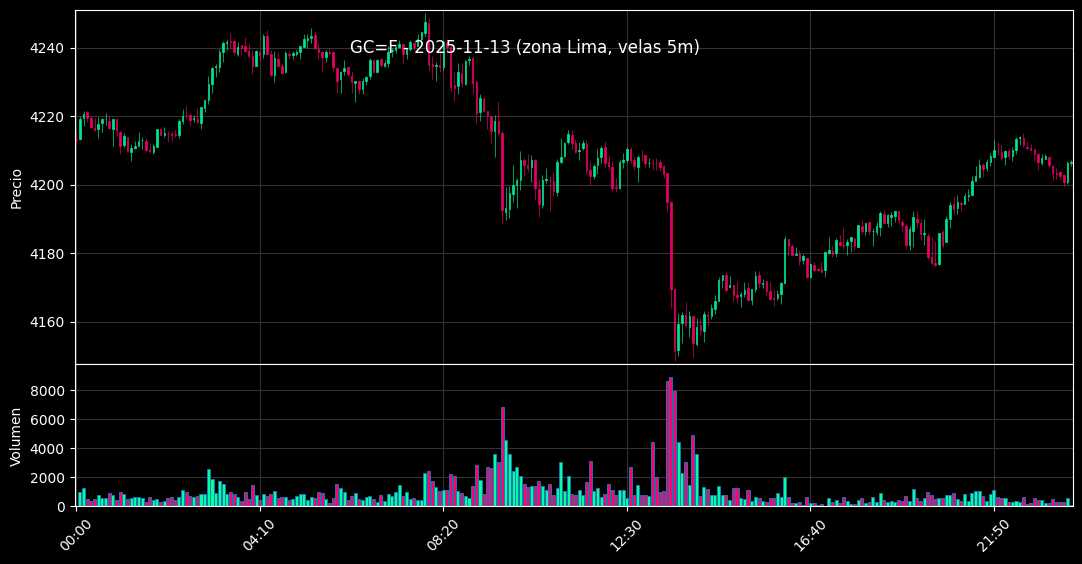

In [33]:
# ===== GRAFICO DEL ORO (GC=F) – DÍA ANTERIOR =====

!pip install -q yfinance mplfinance

import yfinance as yf
import pandas as pd
import mplfinance as mpf
from datetime import datetime, timedelta, time

SIMBOLO = "GC=F"
TZ = "America/Lima"

# Día anterior (hoy - 1)
hoy = datetime.now()
ayer = (hoy - timedelta(days=1)).date()

print(f"Símbolo: {SIMBOLO}")
print(f"Día a graficar (ayer): {ayer}")

start = datetime.combine(ayer, time(0, 0))
end   = start + timedelta(days=1)

df = yf.download(
    SIMBOLO,
    start=start,
    end=end,
    interval="5m",       # velas 5 min
    auto_adjust=False,
    progress=False,
)

if df.empty:
    print("No hay datos intradía para ese día. Prueba cambiar de fecha o símbolo.")
else:
    # --- 1) Aplanar columnas si son MultiIndex ---
    if isinstance(df.columns, pd.MultiIndex):
        new_cols = []
        targets = {"open","high","low","close","adj close","volume"}
        for col in df.columns:
            name = None
            # col es algo como ('Open','GC=F') o ('GC=F','Open')
            for part in col:
                low = str(part).strip().lower()
                if low in targets:
                    name = low
                    break
            if name is None:
                # fallback: último elemento por si acaso
                name = str(col[-1]).strip().lower()
            new_cols.append(name)
        df.columns = new_cols

    # --- 2) Normalizar nombres de columnas ---
    df.columns = [str(c).strip().lower() for c in df.columns]

    # Unificar 'adj close' -> 'close' si hace falta
    if "adj close" in df.columns and "close" not in df.columns:
        df = df.rename(columns={"adj close": "close"})

    required_cols = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        print("Faltan columnas para mplfinance:", missing)
        print("Columnas disponibles:", list(df.columns))
    else:
        # nos quedamos solo con OHLCV y los renombramos en mayúsculas
        df = df[required_cols]
        df.columns = ["Open", "High", "Low", "Close", "Volume"]

        # --- 3) Ajustar zona horaria a Lima ---
        if df.index.tz is None:
            df.index = df.index.tz_localize("UTC").tz_convert(TZ)
        else:
            df.index = df.index.tz_convert(TZ)

        # Solo el día exacto en Lima
        df_dia = df[df.index.date == ayer]

        print(f"Velas encontradas (5m, zona Lima): {len(df_dia)}")

        if df_dia.empty:
            print("No hay velas exactas para ese día (zona Lima).")
        else:
            # --- 4) Estilo neón en fondo negro ---
            mc = mpf.make_marketcolors(
                up='#00FF9F',      # verde neón
                down='#FF006E',    # fucsia neón
                edge='inherit',
                wick='inherit',
                volume='inherit'
            )

            estilo_neon = mpf.make_mpf_style(
                base_mpl_style='dark_background',
                marketcolors=mc,
                facecolor='black',
                figcolor='black',
                gridcolor='#333333',
                rc={
                    'axes.labelcolor': 'white',
                    'xtick.color': 'white',
                    'ytick.color': 'white'
                }
            )

            mpf.plot(
                df_dia,
                type='candle',
                style=estilo_neon,
                volume=True,
                title=f"{SIMBOLO} - {ayer} (zona Lima, velas 5m)",
                ylabel='Precio',
                ylabel_lower='Volumen',
                figratio=(16, 8),
                tight_layout=True
            )

# ===== FIN BLOQUE =====


In [34]:
# ===== GRAFICO INTERACTIVO DEL ORO (GC=F) – DÍA ANTERIOR =====

!pip install -q yfinance plotly

import yfinance as yf
import pandas as pd
from datetime import datetime, timedelta, time

import plotly.graph_objects as go
from plotly.subplots import make_subplots

SIMBOLO = "GC=F"
TZ = "America/Lima"

# --- 1) Día anterior en Lima ---
hoy = datetime.now()
ayer = (hoy - timedelta(days=1)).date()

print(f"Símbolo: {SIMBOLO}")
print(f"Día a graficar (ayer): {ayer}")

start = datetime.combine(ayer, time(0, 0))
end   = start + timedelta(days=1)

# --- 2) Descargar datos intradía (5m) ---
df = yf.download(
    SIMBOLO,
    start=start,
    end=end,
    interval="5m",
    auto_adjust=False,
    progress=False,
)

if df.empty:
    print("No hay datos intradía para ese día. Prueba cambiar de fecha o símbolo.")
else:
    # --- 3) Aplanar columnas MultiIndex (mismo truco robusto) ---
    if isinstance(df.columns, pd.MultiIndex):
        new_cols = []
        targets = {"open", "high", "low", "close", "adj close", "volume"}
        for col in df.columns:
            name = None
            for part in col:
                low = str(part).strip().lower()
                if low in targets:
                    name = low
                    break
            if name is None:
                name = str(col[-1]).strip().lower()
            new_cols.append(name)
        df.columns = new_cols

    # Normalizar nombres
    df.columns = [str(c).strip().lower() for c in df.columns]

    # Unificar adj close -> close si hace falta
    if "adj close" in df.columns and "close" not in df.columns:
        df = df.rename(columns={"adj close": "close"})

    required_cols = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        print("Faltan columnas:", missing)
        print("Columnas disponibles:", list(df.columns))
    else:
        # --- 4) Ajustar zona horaria y filtrar al día exacto ---
        if df.index.tz is None:
            df.index = df.index.tz_localize("UTC").tz_convert(TZ)
        else:
            df.index = df.index.tz_convert(TZ)

        df_dia = df[df.index.date == ayer]

        print(f"Velas encontradas (5m, zona Lima): {len(df_dia)}")

        if df_dia.empty:
            print("No hay velas exactas para ese día (zona Lima).")
        else:
            # ===== 5) FIGURA INTERACTIVA CON PLOTLY =====

            fig = make_subplots(
                rows=2, cols=1,
                shared_xaxes=True,
                vertical_spacing=0.02,
                row_heights=[0.7, 0.3],
                subplot_titles=[f"{SIMBOLO} - {ayer} (zona Lima, velas 5m)", "Volumen"]
            )

            # Candlestick con colores neón
            fig.add_trace(
                go.Candlestick(
                    x=df_dia.index,
                    open=df_dia["open"],
                    high=df_dia["high"],
                    low=df_dia["low"],
                    close=df_dia["close"],
                    increasing_line_color='#00FF9F',
                    increasing_fillcolor='#00FF9F',
                    decreasing_line_color='#FF006E',
                    decreasing_fillcolor='#FF006E',
                    name="Precio"
                ),
                row=1, col=1
            )

            # Volumen (barras)
            fig.add_trace(
                go.Bar(
                    x=df_dia.index,
                    y=df_dia["volume"],
                    name="Volumen",
                    marker_color='#00E5FF',
                    opacity=0.6
                ),
                row=2, col=1
            )

            # Layout general: fondo negro, modo hover unificado
            fig.update_layout(
                template="plotly_dark",
                paper_bgcolor="black",
                plot_bgcolor="black",
                hovermode="x unified",
                xaxis=dict(
                    showgrid=True,
                    gridcolor="#333333",
                ),
                xaxis2=dict(
                    showgrid=True,
                    gridcolor="#333333",
                ),
                yaxis=dict(
                    title="Precio",
                    showgrid=True,
                    gridcolor="#333333",
                ),
                yaxis2=dict(
                    title="Volumen",
                    showgrid=True,
                    gridcolor="#333333",
                ),
                font=dict(color="white"),
                legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
                xaxis_rangeslider_visible=False
            )

            fig.show()

# ===== FIN BLOQUE INTERACTIVO =====


Símbolo: GC=F
Día a graficar (ayer): 2025-11-13
Velas encontradas (5m, zona Lima): 273


In [45]:
# ===== FIX: redefinir build_features con 2 argumentos =====
import pandas as pd

def build_features(hourly: pd.DataFrame, daily5y: pd.DataFrame):
    # copia de diarios
    d = daily5y.copy()
    d["d_ret1"]  = d["close_d"].pct_change(1)
    d["d_rm_5"]  = d["close_d"].rolling(5).mean()
    d["d_rm_20"] = d["close_d"].rolling(20).mean()
    d["d_rm_60"] = d["close_d"].rolling(60).mean()
    d["d_rs_20"] = d["close_d"].rolling(20).std()
    d = d.dropna().astype("float64")

    # alinear diarios a timestamps horarios
    d_h = d.reindex(hourly.index, method="ffill")

    # base horaria
    s = hourly["close_h"].astype("float64")
    X = pd.DataFrame(index=hourly.index)

    # lags horarios
    for L in range(1, 25):
        X[f"h_lag_{L}"] = s.shift(L)

    # retornos y medias móviles
    X["h_ret1"]  = s.pct_change(1)
    X["h_ret3"]  = s.pct_change(3)
    X["h_rm_6"]  = s.rolling(6).mean()
    X["h_rm_24"] = s.rolling(24).mean()
    X["h_rs_24"] = s.rolling(24).std()

    # variables de calendario usando TZ (debes tener TZ="America/Lima" ya definido)
    idx_local = X.index.tz_convert(TZ)
    X["hour"]  = idx_local.hour
    X["dow"]   = idx_local.dayofweek
    X["month"] = idx_local.month

    # unir features diarias
    X = pd.concat([X, d_h], axis=1)

    # limpieza final
    X = X.dropna().astype("float64")
    X.columns = X.columns.map(str)

    y = s.loc[X.index].astype("float64")
    return X, y

# ===== FIN FIX build_features =====


In [46]:
# ======= PREDICCIÓN 24H PARA GC=F CON GRÁFICO INTERACTIVO (FIX) =======
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from datetime import timedelta

TZ = "America/Lima"
SIMBOLO = "GC=F"

# 1) Verificar que el modelo exista en MODEL_STORE
if SIMBOLO not in MODEL_STORE:
    raise Exception(f"⚠️ No hay modelo entrenado para {SIMBOLO}. "
                    f"Ejecuta antes el bloque de entrenamiento.")

info = MODEL_STORE[SIMBOLO]
model = info["model"]
print(f"Usando modelo entrenado para {SIMBOLO}")
print(f"MAE validación guardado: {info['mae']:.4f}")
print("Descargando históricos de nuevo…")

# 2) Descargar nuevamente los datos (mismas funciones del bloque de entrenamiento)
d5   = dl_daily_5y(SIMBOLO)      # diarios 5 años
h730 = dl_hourly_730d(SIMBOLO)   # horarios 730 días

# Aseguramos que h730 tenga la columna close_h en float
h730 = h730.copy()
if isinstance(h730, pd.Series):
    h730 = h730.to_frame(name="close_h")
else:
    if "close_h" not in h730.columns:
        # si viene con otra columna de precio, la renombramos
        first_col = h730.columns[0]
        h730 = h730.rename(columns={first_col: "close_h"})
h730["close_h"] = h730["close_h"].astype("float64")

# 3) Último día real (en zona Lima) para mostrar contexto
last_ts_utc    = h730.index.max()
last_ts_lima   = last_ts_utc.tz_convert(TZ)
last_date_lima = last_ts_lima.date()

# Datos reales del último día (24h aprox)
h_real = h730.copy()
h_real.index = h_real.index.tz_convert(TZ)
h_real_day = h_real[h_real.index.date == last_date_lima]

print(f"Último timestamp horario (UTC):  {last_ts_utc}")
print(f"Último timestamp horario (Lima): {last_ts_lima}")
print(f"Velas reales último día (zona Lima): {len(h_real_day)}")

# 4) Generar predicción multi-step 24h
print("Generando predicción 24h…")

# Partimos de la serie original en UTC (solo precios)
s_ext = h730["close_h"].copy()

future_times_utc = []
future_preds = []

for k in range(1, 25):  # 24 horas futuras
    t_future = last_ts_utc + timedelta(hours=k)

    # Añadimos un timestamp futuro con un valor provisional
    s_tmp = s_ext.copy()
    s_tmp.loc[t_future] = s_tmp.iloc[-1]

    # --- AQUÍ VIENE EL FIX IMPORTANTE ---
    # Si s_tmp es Series -> to_frame; si ya es DataFrame, lo acomodamos
    if isinstance(s_tmp, pd.Series):
        hourly_ext = s_tmp.to_frame(name="close_h")
    elif isinstance(s_tmp, pd.DataFrame):
        tmp = s_tmp.copy()
        if "close_h" not in tmp.columns:
            first_col = tmp.columns[0]
            tmp = tmp.rename(columns={first_col: "close_h"})
        hourly_ext = tmp[["close_h"]]
    else:
        raise TypeError("s_tmp no es ni Series ni DataFrame, algo raro pasó.")
    # ------------------------------------

    # Reconstruimos features y tomamos solo la última fila (el nuevo punto futuro)
    X_all, _ = build_features(hourly_ext, d5)
    X_last = X_all.iloc[[-1]]

    # Predicción para esa hora
    y_hat = model.predict(X_last.to_numpy(dtype="float64"))[0]

    # Guardamos predicción real en la serie extendida
    s_ext.loc[t_future] = y_hat

    future_times_utc.append(t_future)
    future_preds.append(y_hat)

# Convertimos las predicciones a serie con índice en Lima
preds = pd.Series(
    future_preds,
    index=pd.DatetimeIndex(future_times_utc, tz="UTC")
).tz_convert(TZ)

print(f"Predicciones generadas: {len(preds)}")

# 5) Gráfico interactivo con Plotly
fig = go.Figure()

# Serie real (último día)
if not h_real_day.empty:
    fig.add_trace(go.Scatter(
        x=h_real_day.index,
        y=h_real_day["close_h"],
        mode="lines",
        name="Precio real (día actual)",
        line=dict(color="#00F5FF", width=2)  # cian neón
    ))

# Serie de predicción
fig.add_trace(go.Scatter(
    x=preds.index,
    y=preds.values,
    mode="lines+markers",
    name="Predicción próximas 24h",
    line=dict(color="#FF00A8", width=2, dash="dot"),  # fucsia neón
    marker=dict(size=6)
))

fig.update_layout(
    title=f"{SIMBOLO} – Predicción siguientes 24h (zona Lima)",
    xaxis_title="Hora",
    yaxis_title="Precio",
    template="plotly_dark",
    plot_bgcolor="black",
    paper_bgcolor="black",
    hovermode="x unified",
    legend=dict(bgcolor="rgba(0,0,0,0.4)")
)

fig.show()
# ======= FIN BLOQUE PREDICCIÓN 24H (FIX) =======


Usando modelo entrenado para GC=F
MAE validación guardado: 125.0681
Descargando históricos de nuevo…
Último timestamp horario (UTC):  2025-11-14 05:00:00+00:00
Último timestamp horario (Lima): 2025-11-14 00:00:00-05:00
Velas reales último día (zona Lima): 1
Generando predicción 24h…
Predicciones generadas: 24
